In [57]:
%pip install xlrd
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Preprocessing

In [ ]:
#Import the data and necessary libraries
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import RepeatedKFold, cross_validate

filename = "Concrete_Data.xls"
data_csv = pd.read_excel(filename)

print(data_csv)


      Cement (component 1)(kg in a m^3 mixture)  \
0                                         540.0   
1                                         540.0   
2                                         332.5   
3                                         332.5   
4                                         198.6   
...                                         ...   
1025                                      276.4   
1026                                      322.2   
1027                                      148.5   
1028                                      159.1   
1029                                      260.9   

      Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
0                                                   0.0       
1                                                   0.0       
2                                                 142.5       
3                                                 142.5       
4                                                 132.4       
...      

In [59]:
# Checking for NaN values
total_nans = data_csv.isna().sum().sum()

if total_nans == 0:
    print("No NaN values found in the dataset.")
else:
    print(f"Found {total_nans} NaN values in the dataset.")

# Checking for and removing duplicate rows
# (matches the linear regression notebook so all models use the same 1005 rows,
#  and stops identical rows landing in both training and test folds)
num_duplicates = data_csv.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")

data_csv = data_csv.drop_duplicates().reset_index(drop=True)
print("Dataset shape after removing duplicates:", data_csv.shape)

No NaN values found in the dataset.
Number of duplicate rows: 25
Dataset shape after removing duplicates: (1005, 9)


In [60]:
#adding cost column 

# Cost per kg (AUD)
CEMENT_COST = 0.44
BLAST_FURNACE_SLAG_COST = 0.086
FLY_ASH_COST = 0.876
WATER_COST = 0.000115
SUPERPLASTICIZER_COST = 7.66
COARSE_AGGREGATE_COST = 0.09
FINE_AGGREGATE_COST = 0.08

data_csv["Cost"] = (
    data_csv["Cement (component 1)(kg in a m^3 mixture)"] * CEMENT_COST
    + data_csv["Blast Furnace Slag (component 2)(kg in a m^3 mixture)"] * BLAST_FURNACE_SLAG_COST
    + data_csv["Fly Ash (component 3)(kg in a m^3 mixture)"] * FLY_ASH_COST
    + data_csv["Water  (component 4)(kg in a m^3 mixture)"] * WATER_COST
    + data_csv["Superplasticizer (component 5)(kg in a m^3 mixture)"] * SUPERPLASTICIZER_COST
    + data_csv["Coarse Aggregate  (component 6)(kg in a m^3 mixture)"] * COARSE_AGGREGATE_COST
    + data_csv["Fine Aggregate (component 7)(kg in a m^3 mixture)"] * FINE_AGGREGATE_COST
)

print(data_csv[["Cost"]])

            Cost
0     404.448630
1     405.798630
2     289.981220
3     289.981220
4     252.888480
...          ...
1000  418.662454
1001  461.403140
1002  361.926160
1003  324.814394
1004  396.653869

[1005 rows x 1 columns]


In [61]:
#checking for low variance
numeric_variance = data_csv.var(numeric_only=True)
print(numeric_variance)

constant_columns = numeric_variance[numeric_variance == 0].index.tolist()
if len(constant_columns) == 0:
    print("\nNo constant numeric columns were found.")
else:
    print("\nConstant columns:", constant_columns)

Cement (component 1)(kg in a m^3 mixture)                10887.879601
Blast Furnace Slag (component 2)(kg in a m^3 mixture)     7425.364576
Fly Ash (component 3)(kg in a m^3 mixture)                4122.596436
Water  (component 4)(kg in a m^3 mixture)                  455.427169
Superplasticizer (component 5)(kg in a m^3 mixture)         35.041179
Coarse Aggregate  (component 6)(kg in a m^3 mixture)      6018.584052
Fine Aggregate (component 7)(kg in a m^3 mixture)         6454.491667
Age (day)                                                 4062.110923
Concrete compressive strength(MPa, megapascals)            265.194960
Cost                                                      7135.832450
dtype: float64

No constant numeric columns were found.


In [62]:
#feature engineering (computed from RAW kg/m^3 values and raw age, before any scaling)

CEMENT = "Cement (component 1)(kg in a m^3 mixture)"
SLAG = "Blast Furnace Slag (component 2)(kg in a m^3 mixture)"
FLY_ASH = "Fly Ash (component 3)(kg in a m^3 mixture)"
WATER = "Water  (component 4)(kg in a m^3 mixture)"
SUPERPLASTICIZER = "Superplasticizer (component 5)(kg in a m^3 mixture)"
COARSE_AGG = "Coarse Aggregate  (component 6)(kg in a m^3 mixture)"
FINE_AGG = "Fine Aggregate (component 7)(kg in a m^3 mixture)"
AGE = "Age (day)"
TARGET = "Concrete compressive strength(MPa, megapascals) "  # note trailing space in the source file

binder = data_csv[CEMENT] + data_csv[SLAG] + data_csv[FLY_ASH]

data_csv["Water/binder ratio"] = data_csv[WATER] / binder
data_csv["Total aggregate (kg in a m^3 mixture)"] = data_csv[COARSE_AGG] + data_csv[FINE_AGG]
data_csv["log(Age)"] = np.log(data_csv[AGE])  # minimum age is 1 day, so log is defined (log(1) = 0)

print(data_csv[["Water/binder ratio", "Total aggregate (kg in a m^3 mixture)", "log(Age)"]].describe())

       Water/binder ratio  Total aggregate (kg in a m^3 mixture)     log(Age)
count         1005.000000                            1005.000000  1005.000000
mean             0.473139                            1747.063085     3.168492
std              0.125500                             102.230279     1.189466
min              0.235073                            1457.000000     0.000000
25%              0.389522                            1679.000000     1.945910
50%              0.480000                            1758.300000     3.332205
75%              0.561264                            1829.000000     4.025352
max              0.900000                            1970.000000     5.899897


In [63]:
#defining features and target
# Cost is excluded from all feature sets: it is an exact linear combination
# of the ingredient columns and would add perfect multicollinearity.

raw_feature_columns = [CEMENT, SLAG, FLY_ASH, WATER, SUPERPLASTICIZER, COARSE_AGG, FINE_AGG, AGE]

# Engineered set: total aggregate replaces coarse + fine, log(Age) replaces Age,
# and water/binder ratio is added
engineered_feature_columns = [
    CEMENT, SLAG, FLY_ASH, WATER, SUPERPLASTICIZER,
    "Total aggregate (kg in a m^3 mixture)",
    "log(Age)",
    "Water/binder ratio",
]

X_raw = data_csv[raw_feature_columns]   # same 8 inputs as the linear regression model
X_eng = data_csv[engineered_feature_columns]
y = data_csv[TARGET]

print("X_raw shape:", X_raw.shape)
print("X_eng shape:", X_eng.shape)
print("y shape:", y.shape)

X_raw shape: (1005, 8)
X_eng shape: (1005, 8)
y shape: (1005,)


### Linear, Polynomial and Ridge Regression

An analysis is being conducted on the preprocessed data to assess how well a polynomial and ridge regression model can predict concrete compressive strength. This is to be compared against the linear model from the previous attempt.

- 'StandardScaler' is used, working well with the roughly normal distribution of our dataset (see compressive strength ground label spread), ridge applies the same penalty to every coefficient so 'StandardScaler' makes features comparable.
- In the case of polynomials, 'StandardScaler' is applied after 'PolynomialFeatures' so that all terms (squared and interaction terms) are also scaled.


In [64]:
#Splitting data into train/test

from sklearn.model_selection import train_test_split

X_raw_train, X_raw_test, X_eng_train, X_eng_test, y_train, y_test = train_test_split(
    X_raw, X_eng, y, test_size=0.2, random_state=42,
    stratify=pd.qcut(y, q=5, labels=False)   # optional, see note below
)

print("Train:", X_eng_train.shape, " Test:", X_eng_test.shape)

Train: (804, 8)  Test: (201, 8)


In [65]:
#Cross validation with the training set, using the same 5-fold CV as the linear regression 

X_train_sets = {"raw": X_raw_train, "eng": X_eng_train}
X_test_sets  = {"raw": X_raw_test,  "eng": X_eng_test}

models = {
    "Linear (raw)": (make_pipeline(StandardScaler(), LinearRegression()), "raw"),
    "Linear (engineered)": (make_pipeline(StandardScaler(), LinearRegression()), "eng"),
    "Ridge (engineered)": (make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)), "eng"),
    "Poly2 + Ridge (engineered)": (
        make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                      StandardScaler(), RidgeCV(alphas=alphas)), "eng"),
    "Poly3 + Ridge (engineered)": (
        make_pipeline(PolynomialFeatures(degree=3, include_bias=False),
                      StandardScaler(), RidgeCV(alphas=alphas)), "eng"),
}

rows = []
for name, (model, fset) in models.items():
    res = cross_validate(model, X_train_sets[fset], y_train, cv=cv,
                         scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
                         return_train_score=True)
    rmse = -res["test_rmse"]
    rows.append({
        "Model": name,
        "CV RMSE (MPa)": rmse.mean(),
        "RMSE SE": rmse.std(ddof=1) / np.sqrt(len(rmse)),
        "CV R²": res["test_r2"].mean(),
        "Train R²": res["train_r2"].mean(),
        "Fit time (ms)": res["fit_time"].mean() * 1000,
    })

cv_results = pd.DataFrame(rows).round(3)
print(cv_results)

                        Model  CV RMSE (MPa)  RMSE SE  CV R²  Train R²  \
0                Linear (raw)         10.437    0.098  0.575     0.596   
1         Linear (engineered)          7.053    0.082  0.806     0.815   
2          Ridge (engineered)          7.054    0.082  0.806     0.815   
3  Poly2 + Ridge (engineered)          5.929    0.074  0.863     0.886   
4  Poly3 + Ridge (engineered)          5.383    0.097  0.886     0.932   

   Fit time (ms)  
0          1.443  
1          1.317  
2          3.330  
3          6.299  
4         18.185  


### Evaluating

In [66]:
#Evaluating models on the test set
import time
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error

X_test_sets = {"raw": X_raw_test, "eng": X_eng_test}
near_target = y_test.between(25, 35)   # test mixes near the 30 MPa target

rows = []
predictions = {}                       # kept for the plots

for name, (model, fset) in models.items():
    X_tr, X_te = X_train_sets[fset], X_test_sets[fset]

    # Fit on the full training set and time it
    start = time.perf_counter()
    model.fit(X_tr, y_train)
    fit_ms = (time.perf_counter() - start) * 1000

    # Predict on the test set
    y_pred = model.predict(X_te)
    predictions[name] = y_pred

    # Inference time per mix, averaged over repeated runs
    start = time.perf_counter()
    for _ in range(100):
        model.predict(X_te)
    predict_us = (time.perf_counter() - start) / (100 * len(X_te)) * 1e6

    # Simplicity measures from the final estimator in the pipeline
    est = model[-1]
    rows.append({
        "Model": name,
        "Test RMSE (MPa)": root_mean_squared_error(y_test, y_pred),
        "Test MAE (MPa)": mean_absolute_error(y_test, y_pred),
        "Test R²": r2_score(y_test, y_pred),
        "RMSE 25–35 MPa": root_mean_squared_error(y_test[near_target], y_pred[near_target]),
        "Features": est.n_features_in_,
        "Stored values": est.coef_.size + 1,           # coefficients + intercept
        "α": getattr(est, "alpha_", np.nan),           # NaN for plain LinearRegression
        "Fit time (ms)": fit_ms,
        "Predict (µs/mix)": predict_us,
    })

test_results = pd.DataFrame(rows)
print(f"Test mixes in 25–35 MPa: {near_target.sum()} of {len(y_test)}")

Test mixes in 25–35 MPa: 41 of 201


In [67]:
#Test results table
fmt = {
    "Test RMSE (MPa)": "{:.2f}", "Test MAE (MPa)": "{:.2f}", "Test R²": "{:.3f}",
    "RMSE 25–35 MPa": "{:.2f}", "α": "{:.3g}",
    "Fit time (ms)": "{:.1f}", "Predict (µs/mix)": "{:.2f}",
}

display(
    test_results.style
        .format(fmt, na_rep="–")
        .highlight_min(subset=["Test RMSE (MPa)", "Test MAE (MPa)", "RMSE 25–35 MPa"], color="#000000")
        .highlight_max(subset=["Test R²"], color="#000000")
        .hide(axis="index")
        .set_caption("Test-set performance and model simplicity")
)

Model,Test RMSE (MPa),Test MAE (MPa),Test R²,RMSE 25–35 MPa,Features,Stored values,α,Fit time (ms),Predict (µs/mix)
Linear (raw),10.27,8.12,0.632,6.25,8,9,–,2.0,1.85
Linear (engineered),7.43,5.81,0.807,6.30,8,9,–,1.3,1.73
Ridge (engineered),7.43,5.80,0.807,6.29,8,9,0.869,8.4,1.66
Poly2 + Ridge (engineered),6.20,4.64,0.866,5.57,44,45,0.001,6.8,2.00
Poly3 + Ridge (engineered),5.88,4.36,0.879,5.69,164,165,0.00954,25.0,2.36


In [68]:
#Combined test and validation table

cv_renamed = cv_results.rename(columns={
    "CV RMSE (MPa)": "Val RMSE (MPa)", "RMSE SE": "Val RMSE SE",
    "CV R²": "Val R²", "Fit time (ms)": "CV fit time (ms)",
})

summary = cv_renamed.merge(test_results, on="Model")

# One-standard-error rule on validation RMSE
best = summary["Val RMSE (MPa)"].idxmin()
threshold = summary.loc[best, "Val RMSE (MPa)"] + summary.loc[best, "Val RMSE SE"]
summary["Within 1 SE"] = np.where(summary["Val RMSE (MPa)"] <= threshold, "✓", "")

summary = summary[[
    "Model", "Val RMSE (MPa)", "Val RMSE SE", "Within 1 SE",
    "Test RMSE (MPa)", "Val R²", "Test R²", "RMSE 25–35 MPa",
    "Features", "Stored values", "α", "Fit time (ms)", "Predict (µs/mix)",
]]

display(
    summary.style
        .format({**fmt, "Val RMSE (MPa)": "{:.2f}", "Val RMSE SE": "{:.3f}", "Val R²": "{:.3f}"},
                na_rep="–")
        .highlight_min(subset=["Val RMSE (MPa)", "Test RMSE (MPa)"], color="#000000")
        .hide(axis="index")
        .set_caption(f"Validation vs test (1-SE threshold: {threshold:.2f} MPa)")
)

Model,Val RMSE (MPa),Val RMSE SE,Within 1 SE,Test RMSE (MPa),Val R²,Test R²,RMSE 25–35 MPa,Features,Stored values,α,Fit time (ms),Predict (µs/mix)
Linear (raw),10.44,0.098,,10.27,0.575,0.632,6.25,8,9,–,2.0,1.85
Linear (engineered),7.05,0.082,,7.43,0.806,0.807,6.30,8,9,–,1.3,1.73
Ridge (engineered),7.05,0.082,,7.43,0.806,0.807,6.29,8,9,0.869,8.4,1.66
Poly2 + Ridge (engineered),5.93,0.074,,6.20,0.863,0.866,5.57,44,45,0.001,6.8,2.00
Poly3 + Ridge (engineered),5.38,0.097,✓,5.88,0.886,0.879,5.69,164,165,0.00954,25.0,2.36


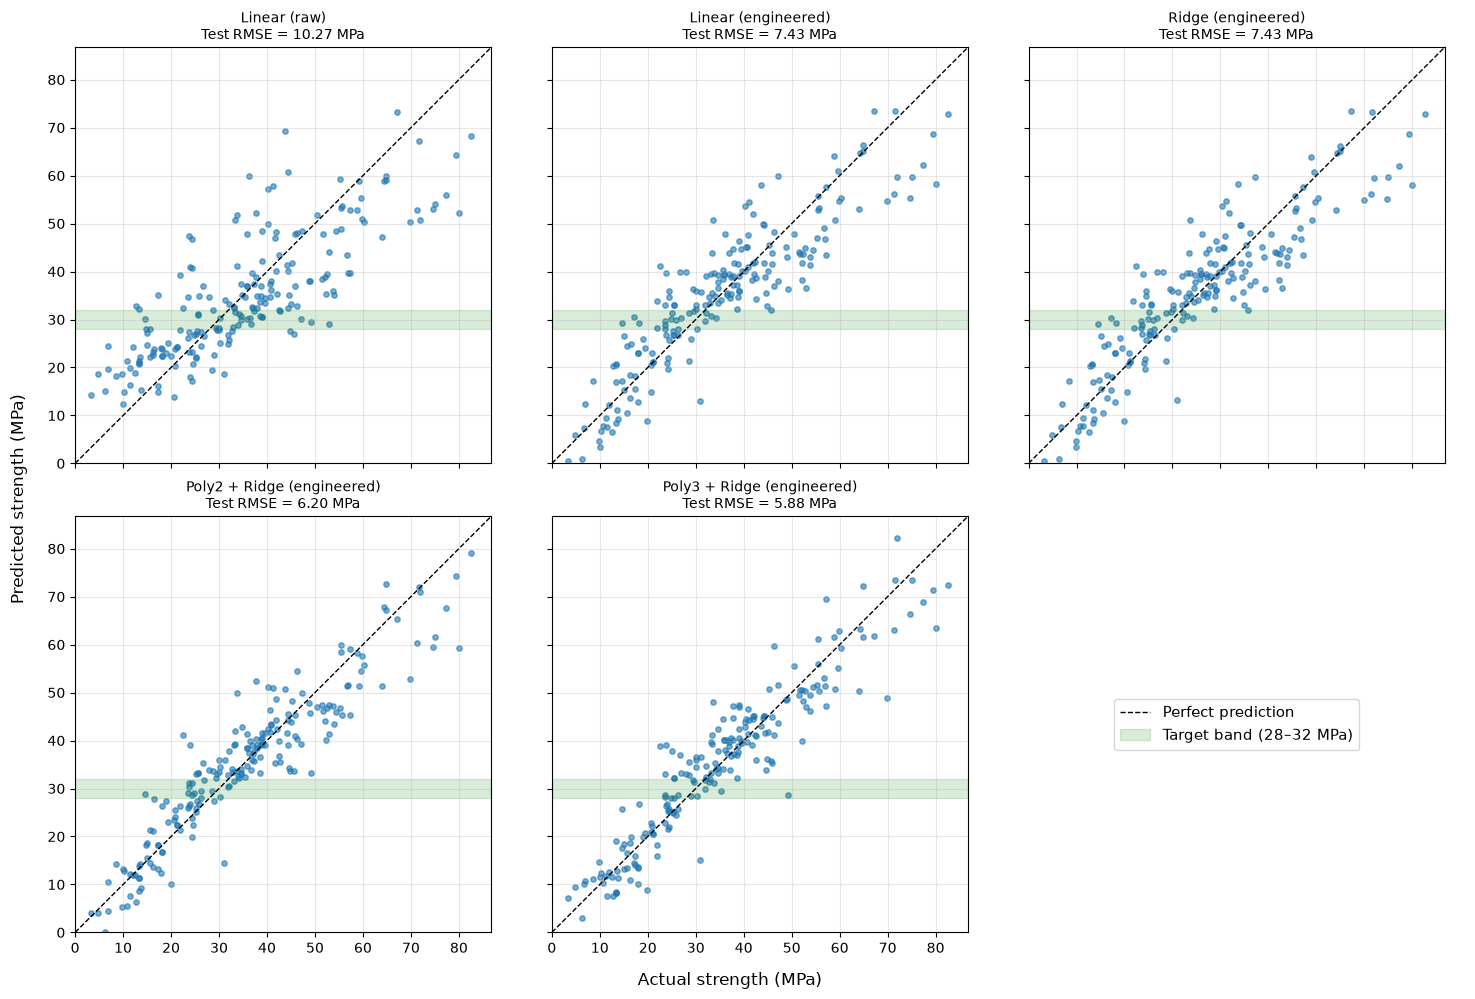

In [69]:
#Predicted vs Actual plots
n = len(predictions)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), sharex=True, sharey=True)
axes = axes.ravel()

all_vals = np.concatenate([y_test.to_numpy(), *predictions.values()])
lims = [min(0, all_vals.min()), all_vals.max() * 1.05]

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, s=15, alpha=0.6)
    ax.plot(lims, lims, "k--", lw=1, label="Perfect prediction")
    ax.axhspan(28, 32, color="green", alpha=0.15, label="Target band (28–32 MPa)")
    ax.set_title(f"{name}\nTest RMSE = {root_mean_squared_error(y_test, y_pred):.2f} MPa",
                 fontsize=10)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

# Use the spare panel for the legend, hide any others
handles, labels = axes[0].get_legend_handles_labels()
for i, ax in enumerate(axes[n:]):
    ax.axis("off")
    if i == 0:
        ax.legend(handles, labels, loc="center", fontsize=11)

fig.supxlabel("Actual strength (MPa)")
fig.supylabel("Predicted strength (MPa)")
fig.tight_layout()
fig.savefig("predicted_vs_actual.png", dpi=300, bbox_inches="tight")   # for your report
plt.show()

### Tree Models

In [70]:
#Define tree models and hyperparameter grids
from sklearn.base import clone
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold, cross_validate
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error

inner_cv = KFold(n_splits=3, shuffle=True, random_state=42)   # for hyperparameter tuning
# `cv` (RepeatedKFold, random_state=42) is reused from the linear notebook,
# so tree and linear models are evaluated on identical folds.

tree_models = {
    "Decision tree": (
        GridSearchCV(
            DecisionTreeRegressor(random_state=42),
            param_grid={"max_depth": [4, 6, 8, 10, 12, None],
                        "min_samples_leaf": [1, 3, 5, 10]},
            cv=inner_cv, scoring="neg_root_mean_squared_error"),
        "eng"),
    "Random forest": (
        GridSearchCV(
            RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
            param_grid={"max_features": [0.33, 0.66, 1.0],
                        "min_samples_leaf": [1, 3, 5]},
            cv=inner_cv, scoring="neg_root_mean_squared_error"),
        "eng"),
    "Hist gradient boosting": (
        GridSearchCV(
            HistGradientBoostingRegressor(max_iter=500, early_stopping=False, random_state=42),
            param_grid={"learning_rate": [0.05, 0.1],
                        "max_leaf_nodes": [15, 31],
                        "min_samples_leaf": [5, 20]},
            cv=inner_cv, scoring="neg_root_mean_squared_error"),
        "eng"),
}

In [71]:
#Cross-validation on the training set for tree models
rows = []
for name, (search, fset) in tree_models.items():
    start = time.perf_counter()
    res = cross_validate(search, X_train_sets[fset], y_train, cv=cv,
                         scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
                         return_train_score=True)
    rmse = -res["test_rmse"]   # sklearn calls the validation fold "test"
    rows.append({
        "Model": name,
        "Val RMSE (MPa)": rmse.mean(),
        "Val RMSE SE": rmse.std(ddof=1) / np.sqrt(len(rmse)),
        "Val R²": res["test_r2"].mean(),
        "Train R²": res["train_r2"].mean(),
    })
    print(f"{name}: done in {time.perf_counter() - start:.0f} s")

tree_cv_results = pd.DataFrame(rows)
display(tree_cv_results.round(3))

Decision tree: done in 4 s
Random forest: done in 119 s
Hist gradient boosting: done in 973 s


,Model,Val RMSE (MPa),Val RMSE SE,Val R²,Train R²
0,Decision tree,6.920,0.127,0.813,0.946
1,Random forest,4.968,0.114,0.903,0.985
2,Hist gradient boosting,4.504,0.165,0.919,0.993


In [72]:
#Evaluating tree models on the test set
def tree_size(est):
    """Return (stored values, total nodes, number of trees) for a fitted tree model.
    Stored values: 2 per split node (feature index, threshold) + 1 per leaf (prediction)."""
    if isinstance(est, HistGradientBoostingRegressor):
        # private attribute: one predictor per boosting iteration
        node_arrays = [p.nodes for it in est._predictors for p in it]
        leaves = sum(int(n["is_leaf"].sum()) for n in node_arrays)
        total = sum(len(n) for n in node_arrays)
        return 2 * (total - leaves) + leaves + 1, total, len(node_arrays)   # +1 baseline
    trees = [est.tree_] if isinstance(est, DecisionTreeRegressor) else [t.tree_ for t in est.estimators_]
    leaves = sum(int((t.children_left == -1).sum()) for t in trees)
    total = sum(t.node_count for t in trees)
    return 2 * (total - leaves) + leaves, total, len(trees)


X_test_sets = {"raw": X_raw_test, "eng": X_eng_test}
near_target = y_test.between(25, 35)

rows = []
tree_predictions = {}

for name, (search, fset) in tree_models.items():
    X_tr, X_te = X_train_sets[fset], X_test_sets[fset]

    search.fit(X_tr, y_train)                 # tunes on the full training set
    best = search.best_estimator_

    # Time a refit of the chosen configuration only
    start = time.perf_counter()
    clone(best).fit(X_tr, y_train)
    fit_ms = (time.perf_counter() - start) * 1000

    y_pred = best.predict(X_te)
    tree_predictions[name] = y_pred

    start = time.perf_counter()
    for _ in range(100):
        best.predict(X_te)
    predict_us = (time.perf_counter() - start) / (100 * len(X_te)) * 1e6

    stored, nodes, n_trees = tree_size(best)

    rows.append({
        "Model": name,
        "Test RMSE (MPa)": root_mean_squared_error(y_test, y_pred),
        "Test MAE (MPa)": mean_absolute_error(y_test, y_pred),
        "Test R²": r2_score(y_test, y_pred),
        "RMSE 25–35 MPa": root_mean_squared_error(y_test[near_target], y_pred[near_target]),
        "Trees": n_trees,
        "Total nodes": nodes,
        "Stored values": stored,
        "Best params": ", ".join(f"{k}={v}" for k, v in search.best_params_.items()),
        "Fit time (ms)": fit_ms,
        "Predict (µs/mix)": predict_us,
    })

tree_test_results = pd.DataFrame(rows)

In [74]:
#Test results table for tree models

tree_fmt = {
    "Test RMSE (MPa)": "{:.2f}", "Test MAE (MPa)": "{:.2f}", "Test R²": "{:.3f}",
    "RMSE 25–35 MPa": "{:.2f}", "Total nodes": "{:,}", "Stored values": "{:,}",
    "Fit time (ms)": "{:.1f}", "Predict (µs/mix)": "{:.2f}",
}

display(
    tree_test_results.style
        .format(tree_fmt)
        .highlight_min(subset=["Test RMSE (MPa)", "Test MAE (MPa)", "RMSE 25–35 MPa"], color="#000000")
        .highlight_max(subset=["Test R²"], color="#000000")
        .hide(axis="index")
        .set_caption("Tree models: test-set performance and model size")
)

Model,Test RMSE (MPa),Test MAE (MPa),Test R²,RMSE 25–35 MPa,Trees,Total nodes,Stored values,Best params,Fit time (ms),Predict (µs/mix)
Decision tree,6.20,4.37,0.866,5.75,1,429,643,"max_depth=12, min_samples_leaf=3",2.3,1.23
Random forest,4.71,3.34,0.923,4.29,300,"301,002","451,353","max_features=0.66, min_samples_leaf=1",171.7,132.13
Hist gradient boosting,4.09,2.74,0.942,3.26,500,"14,500","21,501","learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=5",1107.7,69.48


In [76]:
#Validation and test table for tree models
tree_summary = tree_cv_results.merge(tree_test_results, on="Model")

best_i = tree_summary["Val RMSE (MPa)"].idxmin()
threshold = tree_summary.loc[best_i, "Val RMSE (MPa)"] + tree_summary.loc[best_i, "Val RMSE SE"]
tree_summary["Within 1 SE"] = np.where(tree_summary["Val RMSE (MPa)"] <= threshold, "✓", "")

tree_summary = tree_summary[[
    "Model", "Val RMSE (MPa)", "Val RMSE SE", "Within 1 SE",
    "Test RMSE (MPa)", "Train R²", "Val R²", "Test R²", "RMSE 25–35 MPa",
    "Trees", "Total nodes", "Stored values", "Best params", "Fit time (ms)", "Predict (µs/mix)",
]]

display(
    tree_summary.style
        .format({**tree_fmt, "Val RMSE (MPa)": "{:.2f}", "Val RMSE SE": "{:.3f}",
                 "Train R²": "{:.3f}", "Val R²": "{:.3f}"})
        .highlight_min(subset=["Val RMSE (MPa)", "Test RMSE (MPa)"], color="#000000")
        .hide(axis="index")
        .set_caption(f"Tree models: validation vs test (1-SE threshold: {threshold:.2f} MPa)")
)

Model,Val RMSE (MPa),Val RMSE SE,Within 1 SE,Test RMSE (MPa),Train R²,Val R²,Test R²,RMSE 25–35 MPa,Trees,Total nodes,Stored values,Best params,Fit time (ms),Predict (µs/mix)
Decision tree,6.92,0.127,,6.20,0.946,0.813,0.866,5.75,1,429,643,"max_depth=12, min_samples_leaf=3",2.3,1.23
Random forest,4.97,0.114,,4.71,0.985,0.903,0.923,4.29,300,"301,002","451,353","max_features=0.66, min_samples_leaf=1",171.7,132.13
Hist gradient boosting,4.50,0.165,✓,4.09,0.993,0.919,0.942,3.26,500,"14,500","21,501","learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=5",1107.7,69.48


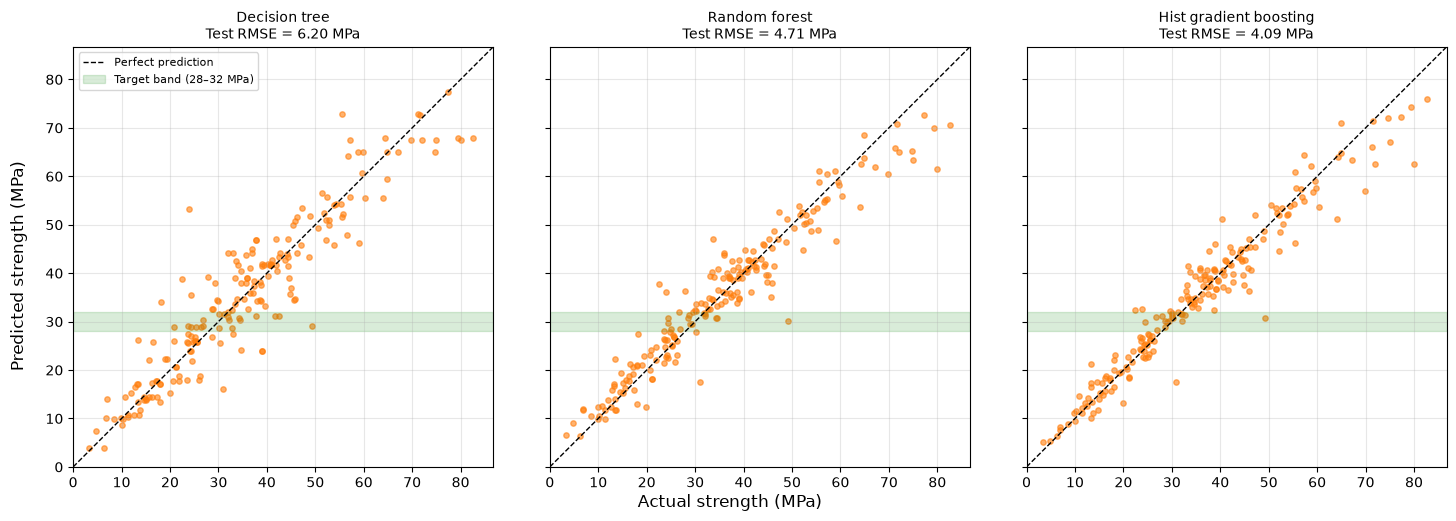

In [77]:
#Predicted vs actual plots for tree models
n = len(tree_predictions)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

all_vals = np.concatenate([y_test.to_numpy(), *tree_predictions.values()])
lims = [min(0, all_vals.min()), all_vals.max() * 1.05]

for ax, (name, y_pred) in zip(axes, tree_predictions.items()):
    ax.scatter(y_test, y_pred, s=15, alpha=0.6, color="tab:orange")
    ax.plot(lims, lims, "k--", lw=1, label="Perfect prediction")
    ax.axhspan(28, 32, color="green", alpha=0.15, label="Target band (28–32 MPa)")
    ax.set_title(f"{name}\nTest RMSE = {root_mean_squared_error(y_test, y_pred):.2f} MPa",
                 fontsize=10)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

# Legend in a spare panel if there is one, otherwise on the first panel
handles, labels = axes[0].get_legend_handles_labels()
spare = axes[n:]
if len(spare):
    for ax in spare:
        ax.axis("off")
    spare[0].legend(handles, labels, loc="center", fontsize=11)
else:
    axes[0].legend(loc="upper left", fontsize=8)

fig.supxlabel("Actual strength (MPa)")
fig.supylabel("Predicted strength (MPa)")
fig.tight_layout()
fig.savefig("tree_predicted_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()

In [79]:
#Summary of all models (linear, polynomial, and tree)
common = ["Model", "Val RMSE (MPa)", "Val RMSE SE", "Test RMSE (MPa)", "Test R²",
          "RMSE 25–35 MPa", "Stored values", "Fit time (ms)", "Predict (µs/mix)"]

overall = pd.concat(
    [summary[common].assign(Family="Linear"), tree_summary[common].assign(Family="Tree")],
    ignore_index=True,
).sort_values("Stored values", ignore_index=True)

best_i = overall["Val RMSE (MPa)"].idxmin()
threshold = overall.loc[best_i, "Val RMSE (MPa)"] + overall.loc[best_i, "Val RMSE SE"]
overall["Within 1 SE"] = np.where(overall["Val RMSE (MPa)"] <= threshold, "✓", "")

overall = overall[["Family"] + common[:3] + ["Within 1 SE"] + common[3:]]

display(
    overall.style
        .format({"Val RMSE (MPa)": "{:.2f}", "Val RMSE SE": "{:.3f}", "Test RMSE (MPa)": "{:.2f}",
                 "Test R²": "{:.3f}", "RMSE 25–35 MPa": "{:.2f}", "Stored values": "{:,}",
                 "Fit time (ms)": "{:.1f}", "Predict (µs/mix)": "{:.2f}"})
        .highlight_min(subset=["Val RMSE (MPa)", "Test RMSE (MPa)"], color="#000000")
        .hide(axis="index")
        .set_caption(f"All models, simplest first (1-SE threshold: {threshold:.2f} MPa)")
)

Family,Model,Val RMSE (MPa),Val RMSE SE,Within 1 SE,Test RMSE (MPa),Test R²,RMSE 25–35 MPa,Stored values,Fit time (ms),Predict (µs/mix)
Linear,Linear (raw),10.44,0.098,,10.27,0.632,6.25,9,2.0,1.85
Linear,Linear (engineered),7.05,0.082,,7.43,0.807,6.30,9,1.3,1.73
Linear,Ridge (engineered),7.05,0.082,,7.43,0.807,6.29,9,8.4,1.66
Linear,Poly2 + Ridge (engineered),5.93,0.074,,6.20,0.866,5.57,45,6.8,2.00
Linear,Poly3 + Ridge (engineered),5.38,0.097,,5.88,0.879,5.69,165,25.0,2.36
Tree,Decision tree,6.92,0.127,,6.20,0.866,5.75,643,2.3,1.23
Tree,Hist gradient boosting,4.50,0.165,✓,4.09,0.942,3.26,"21,501",1107.7,69.48
Tree,Random forest,4.97,0.114,,4.71,0.923,4.29,"451,353",171.7,132.13
